# 3D Array Testing

In [1]:
import pytweezer.phasemask as pm
import numpy as np
import matplotlib.pyplot as plt

In [4]:
dx, dy = 8.0, 12.0
PM = pm.OptimisationBasedPhasemaskGeneratorGPU3D(
                 wavelength_um=0.852,
                 focal_length_mm=17.3,
                 slm_pitch_um=17,
                 slm_res=(1024,1024),
                 input_beam_waist_mm=16,
                 fresnel_f_mm=1072,
                 blaze_dx_dy_um=(40+dx, -8+dy),
                 zernike_coeff_dict={5:1.195, 6:0.725, 7:0.970, 8:0.478, 9:-1.091, 10:0.303, 11:0.021, 12:0.072, 13:0.049})

--- System Configuration ---
SLM Plane Width: 17.41 mm
SLM Plane Height: 17.41 mm
Focal Plane Resolution x (pixel size): 0.8467 um
Focal Plane Resolution y (pixel size): 0.8467 um
Focal Plane Width: 867.04 um
Focal Plane Height: 867.04 um
Fresnel Lens Focal Length: 1072.00 mm
Blazed Grating Displacement (dx, dy): (48.0, 4.0) um


In [3]:
weights = np.ones((5, 5))
spacing = 5.0
w_n, theta_n, x_n, y_n, z_n = PM.generate_weighted_array(weights, 5.0)

z_n[10] = 20.0

terms = [w_n, theta_n, x_n, y_n, z_n]
hologram, terms_opt, metrics = PM.superposition_optimization(terms, max_iter=2000, damping=0.35, verbose=True)

--- Target Generation ---
Grid: 5x5
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.35e-04 | Uniformity: 70.93% | Min/Max ratio: 0.281
Iteration 010 | Mean-Squared Error: 9.08e-06 | Uniformity: 92.47% | Min/Max ratio: 0.753
Iteration 020 | Mean-Squared Error: 4.28e-07 | Uniformity: 98.36% | Min/Max ratio: 0.941
Iteration 030 | Mean-Squared Error: 8.13e-08 | Uniformity: 99.29% | Min/Max ratio: 0.971
Iteration 040 | Mean-Squared Error: 1.81e-08 | Uniformity: 99.66% | Min/Max ratio: 0.986
Iteration 050 | Mean-Squared Error: 4.10e-09 | Uniformity: 99.84% | Min/Max ratio: 0.994
Iteration 060 | Mean-Squared Error: 3.43e-09 | Uniformity: 99.85% | Min/Max ratio: 0.995
Iteration 070 | Mean-Squared Error: 2.39e-09 | Uniformity: 99.88% | Min/Max ratio: 0.995
Iteration 080 | Mean-Squared Error: 1.17e-09 | Uniformity: 99.91% | Min/Max ratio: 0.996
Iteration 090 | Mean-Squared Error: 5.03e-10 | Uniformity: 99.94% | Min/Max ratio: 0.997
It

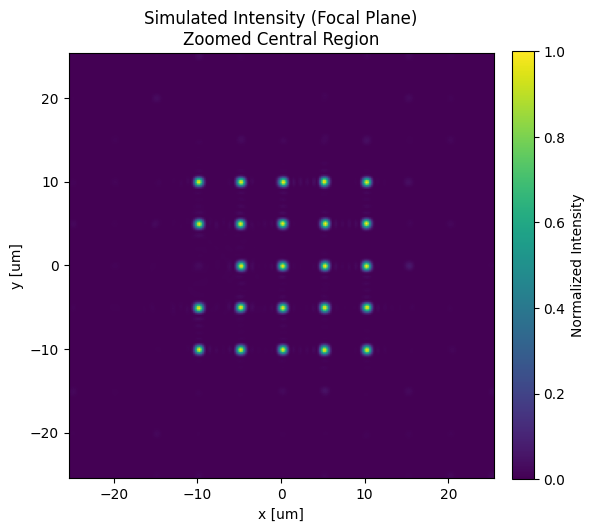

In [97]:
U_foc = PM.simulate_focal_plane(hologram, Nx_pad=2048*2, Ny_pad=2048*2, show=True, zoom_pixels=30, cmap='viridis')

In [9]:
import cupy as cp

def simulate_focal_plane(pm_slm, z_plane = 0.0, Nx_pad=2048, Ny_pad=2048, show=False, zoom_pixels=100, cmap='viridis'):
    X_slm, Y_slm = cp.meshgrid(PM.x_slm, PM.y_slm)
    defocus = - PM.z_scale * z_plane * (X_slm**2 + Y_slm**2)
    am_slm = cp.asarray(PM.generate_source_amplitude())
    field_slm = am_slm * cp.exp(1j * cp.asarray(pm_slm) + defocus)
    field_slm_pad = cp.zeros((Ny_pad, Nx_pad), dtype=cp.complex128)
    field_slm_pad[(Ny_pad - PM.Ny)//2:(Ny_pad + PM.Ny)//2, (Nx_pad - PM.Nx)//2:(Nx_pad + PM.Nx)//2] = field_slm
    field_foc_pad = cp.asnumpy(cp.fft.fftshift(cp.fft.fft2(cp.fft.fftshift(field_slm_pad))))

    if show:
        fig, ax = plt.subplots(1, 1, figsize=(6, 6))
        I_foc = np.abs(field_foc_pad)**2
        norm_intensity = I_foc / I_foc.max()
        x_focal_um = np.linspace(-PM.Nx*PM.dx_f/2, PM.Nx*PM.dx_f/2, Nx_pad)
        y_focal_um = np.linspace(-PM.Ny*PM.dy_f/2, PM.Ny*PM.dy_f/2, Ny_pad)
        im1 = ax.imshow(norm_intensity, 
                            extent=[x_focal_um[0], x_focal_um[-1], y_focal_um[0], y_focal_um[-1]],
                            cmap=cmap)

        zoom_range_um = zoom_pixels * PM.dx_f
        ax.set_xlim(-zoom_range_um, zoom_range_um)
        ax.set_ylim(-zoom_range_um, zoom_range_um)
        ax.grid(False)
        ax.set_title(f"Simulated Intensity (Focal Plane)\nZoomed Central Region")
        ax.set_xlabel("x [um]")
        ax.set_ylabel("y [um]")
        cbar1 = plt.colorbar(im1, ax=ax, fraction=0.046, pad=0.04)
        cbar1.set_label("Normalized Intensity")

    return field_foc_pad

def simulate_focal_field(pm_slm, Nx_pad=2048, Ny_pad=2048, show=False, zoom_pixels=100, z_range=(-10, 10), z_resolution=100, cmap='viridis'):
    X_slm, Y_slm = cp.meshgrid(PM.x_slm, PM.y_slm)
    z_planes = np.linspace(z_range[0], z_range[1], z_resolution)
    field_foc_3D = np.zeros((z_resolution, Ny_pad, Nx_pad), dtype=np.complex128)

    for i, z_plane in enumerate(z_planes):
        defocus = - PM.z_scale * z_plane * (X_slm**2 + Y_slm**2)
        am_slm = cp.asarray(PM.generate_source_amplitude())
        field_slm = am_slm * cp.exp(1j * cp.asarray(pm_slm) + defocus)
        field_slm_pad = cp.zeros((Ny_pad, Nx_pad), dtype=cp.complex128)
        field_slm_pad[(Ny_pad - PM.Ny)//2:(Ny_pad + PM.Ny)//2, (Nx_pad - PM.Nx)//2:(Nx_pad + PM.Nx)//2] = field_slm
        field_foc_pad = cp.asnumpy(cp.fft.fftshift(cp.fft.fft2(cp.fft.fftshift(field_slm_pad))))
        field_foc_3D[i] = field_foc_pad

    if show:
        fig, ax = plt.subplots(1, 1, figsize=(6, 6))
        I_foc = np.abs(field_foc_pad)**2
        norm_intensity = I_foc / I_foc.max()
        x_focal_um = np.linspace(-PM.Nx*PM.dx_f/2, PM.Nx*PM.dx_f/2, Nx_pad)
        y_focal_um = np.linspace(-PM.Ny*PM.dy_f/2, PM.Ny*PM.dy_f/2, Ny_pad)
        im1 = ax.imshow(norm_intensity, 
                            extent=[x_focal_um[0], x_focal_um[-1], y_focal_um[0], y_focal_um[-1]],
                            cmap=cmap)

        zoom_range_um = zoom_pixels * PM.dx_f
        ax.set_xlim(-zoom_range_um, zoom_range_um)
        ax.set_ylim(-zoom_range_um, zoom_range_um)
        ax.grid(False)
        ax.set_title(f"Simulated Intensity (Focal Plane)\nZoomed Central Region")
        ax.set_xlabel("x [um]")
        ax.set_ylabel("y [um]")
        cbar1 = plt.colorbar(im1, ax=ax, fraction=0.046, pad=0.04)
        cbar1.set_label("Normalized Intensity")

    return field_foc_3D

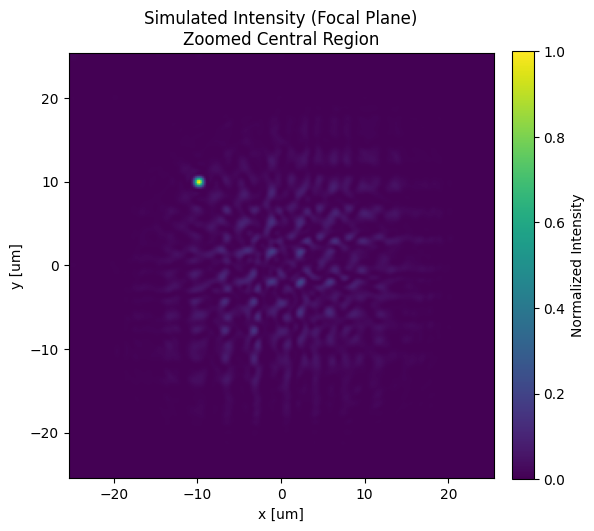

In [52]:
U_foc = simulate_focal_plane(hologram, z_plane=20.0, Nx_pad=2048*2, Ny_pad=2048*2, show=True, zoom_pixels=30, cmap='viridis')

In [54]:
U_foc = simulate_focal_field(hologram, Nx_pad=2048, Ny_pad=2048, show=False, zoom_pixels=30, z_range=(-50, 50), z_resolution=100, cmap='viridis')

In [55]:
I_foc = np.abs(U_foc)**2

Text(0, 0.5, 'y [um]')

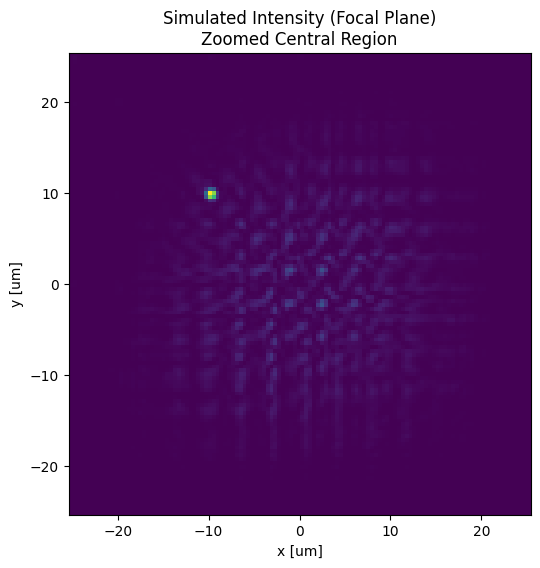

In [62]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
I_foc_z = I_foc[70]
norm_intensity = I_foc_z / I_foc_z.max()
x_focal_um = np.linspace(-PM.Nx*PM.dx_f/2, PM.Nx*PM.dx_f/2, 2048)
y_focal_um = np.linspace(-PM.Ny*PM.dy_f/2, PM.Ny*PM.dy_f/2, 2048)
im1 = ax.imshow(norm_intensity, 
                    extent=[x_focal_um[0], x_focal_um[-1], y_focal_um[0], y_focal_um[-1]],
                    cmap='viridis')

zoom_range_um = 30 * PM.dx_f
ax.set_xlim(-zoom_range_um, zoom_range_um)
ax.set_ylim(-zoom_range_um, zoom_range_um)
ax.grid(False)
ax.set_title(f"Simulated Intensity (Focal Plane)\nZoomed Central Region")
ax.set_xlabel("x [um]")
ax.set_ylabel("y [um]")

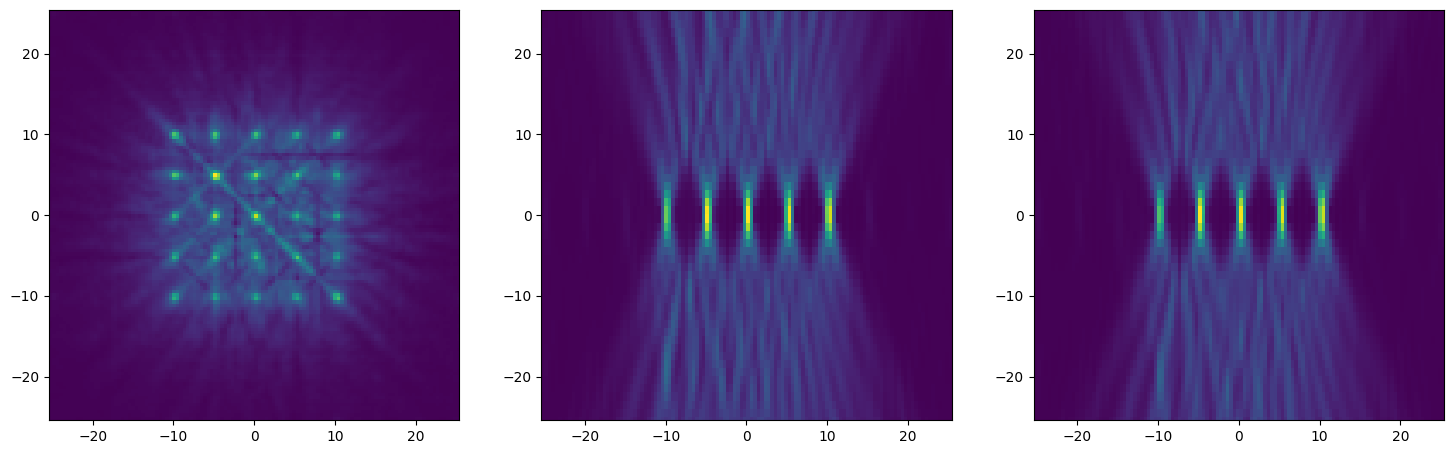

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(6*3, 6))
zoom_range_um = 30 * PM.dx_f
x_focal_um = np.linspace(-PM.Nx*PM.dx_f/2, PM.Nx*PM.dx_f/2, 2048)
y_focal_um = np.linspace(-PM.Ny*PM.dy_f/2, PM.Ny*PM.dy_f/2, 2048)
z_focal_um = np.linspace(-50, 50, 100)  # Assuming z_range=(-50, 50) and z_resolution=100

I_foc_xy = I_foc.sum(axis=0)  # Sum over z-axis to get the xy-plane intensity
norm_intensity_xy = I_foc_xy / I_foc_xy.max()
im1 = ax[0].imshow(norm_intensity_xy, 
                extent=[x_focal_um[0], x_focal_um[-1], y_focal_um[0], y_focal_um[-1]],
                cmap='viridis')
ax[0].set_xlim(-zoom_range_um, zoom_range_um)
ax[0].set_ylim(-zoom_range_um, zoom_range_um)
ax[0].grid(False)

I_foc_xz = I_foc.sum(axis=1)  # Sum over z-axis to get the xz-plane intensity
norm_intensity_xz = I_foc_xz / I_foc_xz.max()
im2 = ax[1].imshow(norm_intensity_xz, 
                extent=[x_focal_um[0], x_focal_um[-1], z_focal_um[0], z_focal_um[-1]],
                cmap='viridis')
ax[1].set_xlim(-zoom_range_um, zoom_range_um)
ax[1].set_ylim(-zoom_range_um, zoom_range_um)
ax[1].grid(False)

I_foc_yz = I_foc.sum(axis=2)  # Sum over z-axis to get the yz-plane intensity
norm_intensity_yz = I_foc_yz / I_foc_yz.max()
im3 = ax[2].imshow(norm_intensity_yz, 
                extent=[y_focal_um[0], y_focal_um[-1], z_focal_um[0], z_focal_um[-1]],
                cmap='viridis')
ax[2].set_xlim(-zoom_range_um, zoom_range_um)
ax[2].set_ylim(-zoom_range_um, zoom_range_um)
ax[2].grid(False)

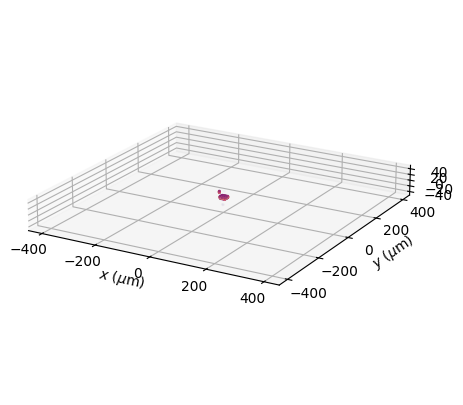

In [65]:
import numpy as np
import matplotlib.pyplot as plt

# I_foc : intensity, shape (nz, ny, nx), indexed [z, y, x]
# xs, ys, zs : coordinate axes (e.g. in micrometres)

zs = np.linspace(-50, 50, 100)  # z-coordinates
ys = np.linspace(-PM.Ny*PM.dy_f/2, PM.Ny*PM.dy_f/2, 2048)
xs = np.linspace(-PM.Nx*PM.dx_f/2, PM.Nx*PM.dx_f/2, 2048)
Z, Y, X = np.meshgrid(zs, ys, xs, indexing="ij")

THRESH  = 0.2      # keep voxels above this fraction of the maximum
GAMMA   = 1.0      # <1 brightens dim voxels, >1 emphasises the peaks
MAX_PTS = 50_000   # matplotlib slows down beyond a few 1e4 points

# ---- select voxels and map intensity to colour and opacity ----------------
In = I_foc / I_foc.max()
keep = In > THRESH
x, y, z, v = X[keep], Y[keep], Z[keep], In[keep]
if v.size > MAX_PTS:                       # keep the brightest if too many
    top = np.argsort(v)[-MAX_PTS:]
    x, y, z, v = x[top], y[top], z[top], v[top]

order = np.argsort(v)                      # draw bright points last
x, y, z, v = x[order], y[order], z[order], v[order]

rgba = plt.get_cmap("magma")(v)                          # colour encodes intensity
rgba[:, 3] = ((v - THRESH)/(1 - THRESH))**GAMMA          # opacity: 0 at threshold, 1 at max

# ---- plot -----------------------------------------------------------------
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection="3d")
ax.scatter(x, y, z, c=rgba, s=4, linewidths=0, depthshade=False)
ax.set_xlabel(r"$x$ ($\mu$m)"); ax.set_ylabel(r"$y$ ($\mu$m)"); ax.set_zlabel(r"$z$ ($\mu$m)")
ax.set_xlim(xs[0], xs[-1]); ax.set_ylim(ys[0], ys[-1]); ax.set_zlim(zs[0], zs[-1])
ax.set_box_aspect((np.ptp(xs), np.ptp(ys), np.ptp(zs)))  # true physical proportions
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.set_major_locator(plt.MaxNLocator(5))           # avoid crowded tick labels
ax.view_init(elev=20, azim=-60)
plt.show()

In [82]:
U_foc = simulate_focal_field(hologram, Nx_pad=2048*2, Ny_pad=2048*2, show=False, zoom_pixels=30, z_range=(-50, 50), z_resolution=100*2, cmap='viridis')
I_foc = np.abs(U_foc)**2

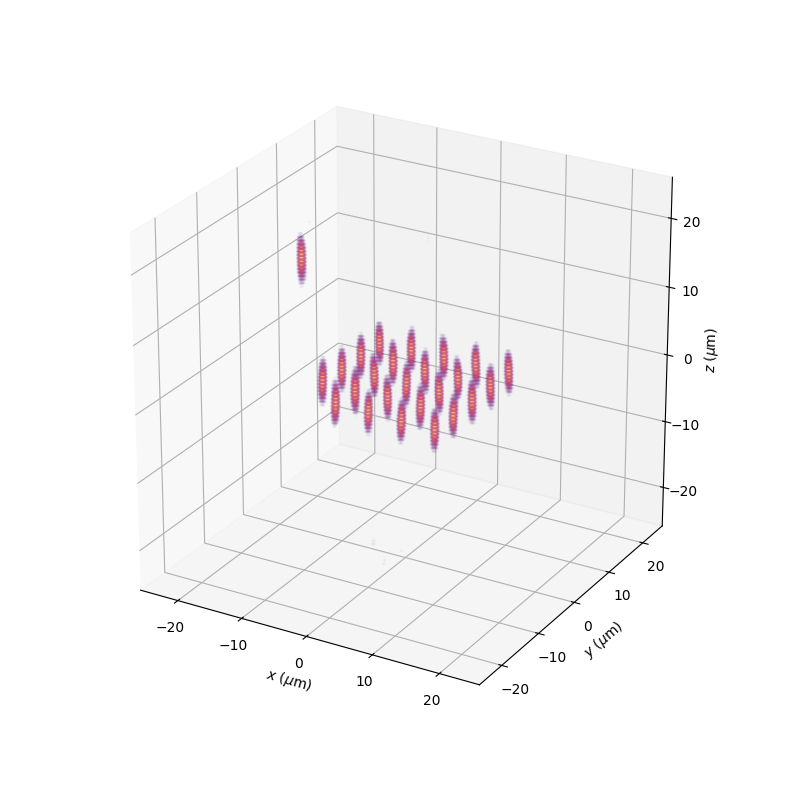

In [87]:
import numpy as np
import matplotlib.pyplot as plt

# I_foc : intensity, shape (nz, ny, nx), indexed [z, y, x]
# xs, ys, zs : coordinate axes (e.g. in micrometres)

zs = np.linspace(-50, 50, 100*2)  # z-coordinates
ys = np.linspace(-PM.Ny*PM.dy_f/2, PM.Ny*PM.dy_f/2, 2048*2)
xs = np.linspace(-PM.Nx*PM.dx_f/2, PM.Nx*PM.dx_f/2, 2048*2)

# ---- settings -------------------------------------------------------------
x_window = 50.0    # full width of the region shown, centred on the origin
y_window = 50.0    # (None = show the whole axis)
z_window = 50.0
THRESH      = 0.2      # keep voxels above this fraction of the reference maximum
GAMMA       = 1.0      # <1 brightens dim voxels, >1 emphasises the peaks
NORM_GLOBAL = True     # True: normalise to the max of the whole volume, so zooming
                       # doesn't change brightness. False: to the max inside the window
MAX_PTS     = 50_000

# ---- crop to the window ---------------------------------------------------
def window_mask(axis, width):
    return np.ones(axis.size, bool) if width is None else np.abs(axis) <= width/2

mx, my, mz = window_mask(xs, x_window), window_mask(ys, y_window), window_mask(zs, z_window)
I_win = I_foc[np.ix_(mz, my, mx)]
xw, yw, zw = xs[mx], ys[my], zs[mz]

# ---- select voxels and map intensity to colour and opacity ----------------
In = I_win / (I_foc.max() if NORM_GLOBAL else I_win.max())
Z, Y, X = np.meshgrid(zw, yw, xw, indexing="ij")
keep = In > THRESH
x, y, z, v = X[keep], Y[keep], Z[keep], In[keep]
if v.size > MAX_PTS:
    top = np.argsort(v)[-MAX_PTS:]
    x, y, z, v = x[top], y[top], z[top], v[top]
order = np.argsort(v)                                    # bright points drawn last
x, y, z, v = x[order], y[order], z[order], v[order]
rgba = plt.get_cmap("magma")(v)
rgba[:, 3] = np.clip((v - THRESH)/(1 - THRESH), 0, 1)**GAMMA

# ---- plot -----------------------------------------------------------------
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection="3d")
ax.scatter(x, y, z, c=rgba, s=4, linewidths=0, depthshade=False)
ax.set_xlabel(r"$x$ ($\mu$m)"); ax.set_ylabel(r"$y$ ($\mu$m)"); ax.set_zlabel(r"$z$ ($\mu$m)")
ax.set_xlim(xw[0], xw[-1]); ax.set_ylim(yw[0], yw[-1]); ax.set_zlim(zw[0], zw[-1])
ax.set_box_aspect((np.ptp(xw), np.ptp(yw), np.ptp(zw)), zoom=0.85)  # true proportions; zoom<1 keeps labels inside
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.set_major_locator(plt.MaxNLocator(5))
ax.view_init(elev=25, azim=-60)
plt.show()

---

In [99]:
U_foc = simulate_focal_field(hologram, Nx_pad=2048, Ny_pad=2048, show=False, zoom_pixels=30, z_range=(-50, 50), z_resolution=100, cmap='viridis')

In [100]:
I_foc = np.abs(U_foc)**2

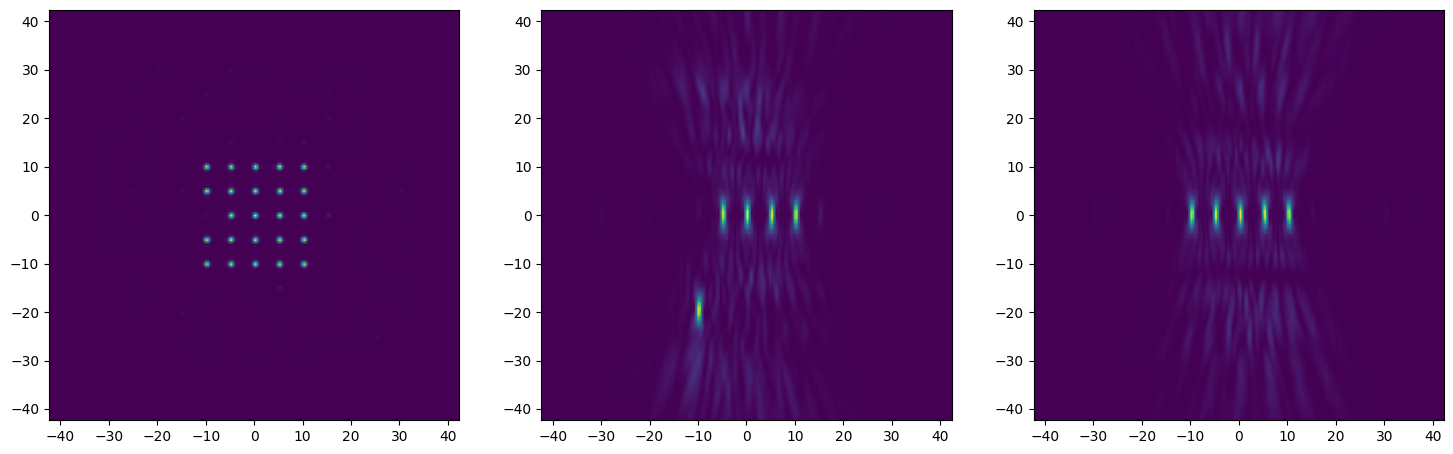

In [ ]:

fig, ax = plt.subplots(1, 3, figsize=(6*3, 6))
zoom_range_um = 50 * PM.dx_f
x_focal_um = np.linspace(-PM.Nx*PM.dx_f/2, PM.Nx*PM.dx_f/2, 2048)
y_focal_um = np.linspace(-PM.Ny*PM.dy_f/2, PM.Ny*PM.dy_f/2, 2048)
z_focal_um = np.linspace(-50, 50, 100)  # Assuming z_range=(-50, 50) and z_resolution=100

I_foc_xy = I_foc[50, :, :]  # Sum over z-axis to get the xy-plane intensity
norm_intensity_xy = I_foc_xy / I_foc_xy.max()
im1 = ax[0].imshow(norm_intensity_xy, 
                extent=[x_focal_um[0], x_focal_um[-1], y_focal_um[0], y_focal_um[-1]],
                cmap='viridis')
ax[0].set_xlim(-zoom_range_um, zoom_range_um)
ax[0].set_ylim(-zoom_range_um, zoom_range_um)
ax[0].grid(False)

I_foc_xz = I_foc[:, 2048//2, :]  # Sum over z-axis to get the xz-plane intensity
norm_intensity_xz = I_foc_xz / I_foc_xz.max()
im2 = ax[1].imshow(norm_intensity_xz, 
                extent=[x_focal_um[0], x_focal_um[-1], z_focal_um[0], z_focal_um[-1]],
                cmap='viridis')
ax[1].set_xlim(-zoom_range_um, zoom_range_um)
ax[1].set_ylim(-zoom_range_um, zoom_range_um)
ax[1].grid(False)

I_foc_yz = I_foc[:, :, 2048//2]  # Sum over z-axis to get the yz-plane intensity
norm_intensity_yz = I_foc_yz / I_foc_yz.max()
im3 = ax[2].imshow(norm_intensity_yz, 
                extent=[y_focal_um[0], y_focal_um[-1], z_focal_um[0], z_focal_um[-1]],
                cmap='viridis')
ax[2].set_xlim(-zoom_range_um, zoom_range_um)
ax[2].set_ylim(-zoom_range_um, zoom_range_um)
ax[2].grid(False)

---
## Testing 3D Rearrangement Code

In [3]:
dx, dy = 8.0, 12.0
PM = pm.OptimisationBasedPhasemaskGeneratorGPU3D(
                 wavelength_um=0.852,
                 focal_length_mm=17.3,
                 slm_pitch_um=17,
                 slm_res=(1024,1024),
                 input_beam_waist_mm=16,
                 fresnel_f_mm=1072,
                 blaze_dx_dy_um=(40+dx, -8+dy),
                 zernike_coeff_dict={5:1.195, 6:0.725, 7:0.970, 8:0.478, 9:-1.091, 10:0.303, 11:0.021, 12:0.072, 13:0.049})

--- System Configuration ---
SLM Plane Width: 17.41 mm
SLM Plane Height: 17.41 mm
Focal Plane Resolution x (pixel size): 0.8467 um
Focal Plane Resolution y (pixel size): 0.8467 um
Focal Plane Width: 867.04 um
Focal Plane Height: 867.04 um
Fresnel Lens Focal Length: 1072.00 mm
Blazed Grating Displacement (dx, dy): (48.0, 4.0) um


In [46]:
weights = np.ones((20, 20))
spacing = 5.0
w_n, theta_n, x_n, y_n, z_n = PM.generate_weighted_array(weights, 5.0)
#z_n = np.random.uniform(-5, 5, size=z_n.shape)  # Random z positions for testing
terms1 = [w_n, theta_n, x_n, y_n, z_n]
hologram1, terms_opt1, metrics = PM.superposition_optimization(terms1, max_iter=2000, damping=0.35, verbose=True)

--- Target Generation ---
Grid: 20x20
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.06e-06 | Uniformity: 58.82% | Min/Max ratio: 0.034
Iteration 010 | Mean-Squared Error: 2.27e-08 | Uniformity: 93.97% | Min/Max ratio: 0.694
Iteration 020 | Mean-Squared Error: 4.32e-09 | Uniformity: 97.37% | Min/Max ratio: 0.852
Iteration 030 | Mean-Squared Error: 1.43e-09 | Uniformity: 98.49% | Min/Max ratio: 0.899
Iteration 040 | Mean-Squared Error: 3.74e-10 | Uniformity: 99.23% | Min/Max ratio: 0.949
Iteration 050 | Mean-Squared Error: 4.86e-10 | Uniformity: 99.12% | Min/Max ratio: 0.942
Iteration 060 | Mean-Squared Error: 5.18e-10 | Uniformity: 99.09% | Min/Max ratio: 0.947
Iteration 070 | Mean-Squared Error: 4.55e-10 | Uniformity: 99.15% | Min/Max ratio: 0.953
Iteration 080 | Mean-Squared Error: 5.77e-10 | Uniformity: 99.04% | Min/Max ratio: 0.940
Iteration 090 | Mean-Squared Error: 3.06e-10 | Uniformity: 99.30% | Min/Max ratio: 0.955


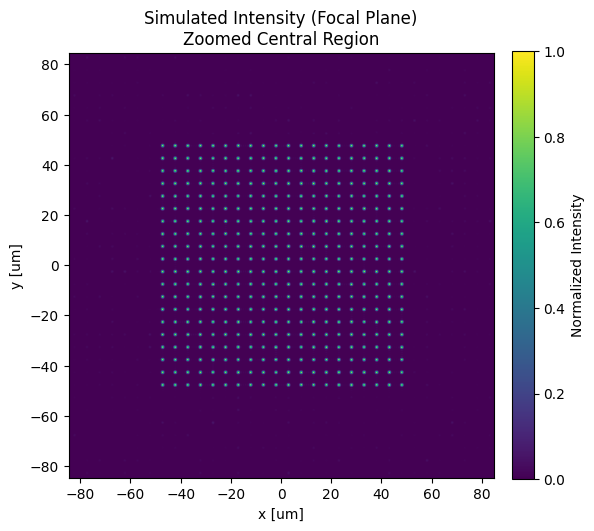

In [47]:
U_foc = PM.simulate_focal_plane(hologram1, Nx_pad=2048*2, Ny_pad=2048*2, show=True, zoom_pixels=100, cmap='viridis')

In [48]:
weights = np.ones((14, 14))
spacing = 5.0
w_n, theta_n, x_n, y_n, z_n = PM.generate_weighted_array(weights, 5.0)

terms2 = [w_n, theta_n, x_n, y_n, z_n]
hologram2, terms_opt2, metrics = PM.superposition_optimization(terms2, max_iter=2000, damping=0.35, verbose=True)

--- Target Generation ---
Grid: 14x14
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 4.15e-06 | Uniformity: 60.08% | Min/Max ratio: 0.073
Iteration 010 | Mean-Squared Error: 9.78e-08 | Uniformity: 93.87% | Min/Max ratio: 0.663
Iteration 020 | Mean-Squared Error: 2.58e-08 | Uniformity: 96.85% | Min/Max ratio: 0.828
Iteration 030 | Mean-Squared Error: 5.88e-09 | Uniformity: 98.50% | Min/Max ratio: 0.926
Iteration 040 | Mean-Squared Error: 4.79e-09 | Uniformity: 98.64% | Min/Max ratio: 0.928
Iteration 050 | Mean-Squared Error: 4.46e-09 | Uniformity: 98.69% | Min/Max ratio: 0.925
Iteration 060 | Mean-Squared Error: 2.03e-09 | Uniformity: 99.12% | Min/Max ratio: 0.957
Iteration 070 | Mean-Squared Error: 1.46e-09 | Uniformity: 99.25% | Min/Max ratio: 0.957
Iteration 080 | Mean-Squared Error: 1.07e-09 | Uniformity: 99.36% | Min/Max ratio: 0.966
Iteration 090 | Mean-Squared Error: 2.24e-09 | Uniformity: 99.07% | Min/Max ratio: 0.949


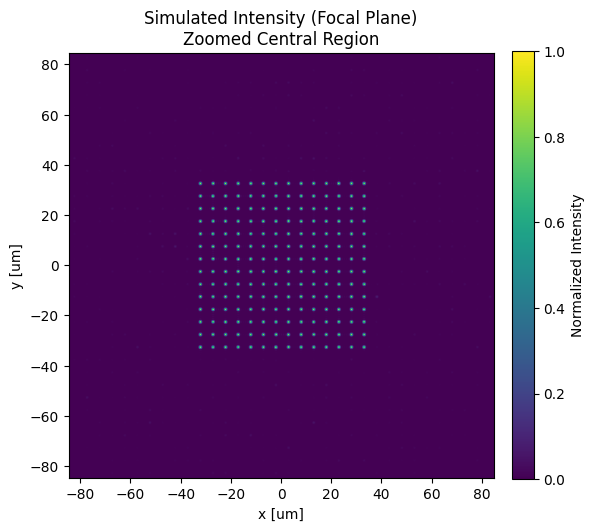

In [49]:
U_foc = PM.simulate_focal_plane(hologram2, Nx_pad=2048*2, Ny_pad=2048*2, show=True, zoom_pixels=100, cmap='viridis')

In [80]:
# Test occupancy mask

occupancy_mask = np.random.choice([False, True], size=(20, 20), p=[0.5, 0.5]).flatten()

In [90]:
import cupy as cp

frames = PM.iter_rearrangement_sequence(terms_opt1, terms_opt2, occupancy_mask, d0=0.25,
                                profile="linear", 
                                refine_iters=1, refine_damping=0.35,
                                init_refine_iters=1, init_refine_damping=0.35,
                                to_host=False)

holograms = [PM.superimpose([frame/PM.uint8_scale - cp.pi, -PM.fresnel, -PM.blaze, - PM.zernike])for frame in frames]

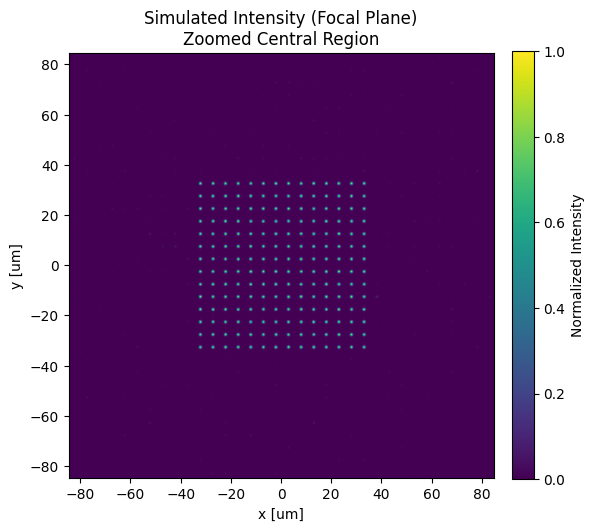

In [91]:
n = -2
hologram_n = holograms[n]
U_foc = PM.simulate_focal_plane(hologram_n, Nx_pad=2048*2, Ny_pad=2048*2, show=True, zoom_pixels=100, cmap='viridis')

w_n, theta_n, x_n, y_n, z_n = terms_opt2
I_n, phi_n = PM.evaluate_traps(hologram_n, x_n, y_n, z_n)

In [92]:
print("Std intensities:", np.std(I_n/I_n.mean()))

Std intensities: 0.029431193111532576


---
## Testing 3D Transport Code

In [55]:
def simulate_focal_field(pm_slm, Nx_pad=2048, Ny_pad=2048, show=False, zoom_pixels=100, z_range=(-10, 10), z_resolution=100, cmap='viridis'):
    X_slm, Y_slm = cp.meshgrid(PM.x_slm, PM.y_slm)
    z_planes = np.linspace(z_range[0], z_range[1], z_resolution)
    field_foc_3D = np.zeros((z_resolution, Ny_pad, Nx_pad), dtype=np.complex128)

    for i, z_plane in enumerate(z_planes):
        defocus = - PM.z_scale * z_plane * (X_slm**2 + Y_slm**2)
        am_slm = cp.asarray(PM.generate_source_amplitude())
        field_slm = am_slm * cp.exp(1j * cp.asarray(pm_slm) + defocus)
        field_slm_pad = cp.zeros((Ny_pad, Nx_pad), dtype=cp.complex128)
        field_slm_pad[(Ny_pad - PM.Ny)//2:(Ny_pad + PM.Ny)//2, (Nx_pad - PM.Nx)//2:(Nx_pad + PM.Nx)//2] = field_slm
        field_foc_pad = cp.asnumpy(cp.fft.fftshift(cp.fft.fft2(cp.fft.fftshift(field_slm_pad))))
        field_foc_3D[i] = field_foc_pad

    if show:
        fig, ax = plt.subplots(1, 1, figsize=(6, 6))
        I_foc = np.abs(field_foc_pad)**2
        norm_intensity = I_foc / I_foc.max()
        x_focal_um = np.linspace(-PM.Nx*PM.dx_f/2, PM.Nx*PM.dx_f/2, Nx_pad)
        y_focal_um = np.linspace(-PM.Ny*PM.dy_f/2, PM.Ny*PM.dy_f/2, Ny_pad)
        im1 = ax.imshow(norm_intensity, 
                            extent=[x_focal_um[0], x_focal_um[-1], y_focal_um[0], y_focal_um[-1]],
                            cmap=cmap)

        zoom_range_um = zoom_pixels * PM.dx_f
        ax.set_xlim(-zoom_range_um, zoom_range_um)
        ax.set_ylim(-zoom_range_um, zoom_range_um)
        ax.grid(False)
        ax.set_title(f"Simulated Intensity (Focal Plane)\nZoomed Central Region")
        ax.set_xlabel("x [um]")
        ax.set_ylabel("y [um]")
        cbar1 = plt.colorbar(im1, ax=ax, fraction=0.046, pad=0.04)
        cbar1.set_label("Normalized Intensity")

    return field_foc_3D

In [3]:
dx, dy = 8.0, 12.0
PM = pm.OptimisationBasedPhasemaskGeneratorGPU3D(
                 wavelength_um=0.852,
                 focal_length_mm=17.3,
                 slm_pitch_um=17,
                 slm_res=(1024,1024),
                 input_beam_waist_mm=16,
                 fresnel_f_mm=1072,
                 blaze_dx_dy_um=(40+dx, -8+dy),
                 zernike_coeff_dict={5:1.195, 6:0.725, 7:0.970, 8:0.478, 9:-1.091, 10:0.303, 11:0.021, 12:0.072, 13:0.049})

--- System Configuration ---
SLM Plane Width: 17.41 mm
SLM Plane Height: 17.41 mm
Focal Plane Resolution x (pixel size): 0.8467 um
Focal Plane Resolution y (pixel size): 0.8467 um
Focal Plane Width: 867.04 um
Focal Plane Height: 867.04 um
Fresnel Lens Focal Length: 1072.00 mm
Blazed Grating Displacement (dx, dy): (48.0, 4.0) um


In [19]:
terms = [np.array([1, 1, 1]), 
        np.random.uniform(-np.pi/2, np.pi/2, size=(3,)), 
        np.array([-2.5, 2.5, 7.5]), 
        np.array([0, 0, 0]),
        np.array([0, 0, 0])]

hologram1, terms_opt1, metrics = PM.superposition_optimization(terms, max_iter=2000, damping=0.35, verbose=True)

--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 3.82e-04 | Uniformity: 94.13% | Min/Max ratio: 0.877
Iteration 010 | Mean-Squared Error: 5.92e-09 | Uniformity: 99.98% | Min/Max ratio: 0.999
Iteration 020 | Mean-Squared Error: 1.93e-08 | Uniformity: 99.96% | Min/Max ratio: 0.999
Iteration 030 | Mean-Squared Error: 2.84e-08 | Uniformity: 99.95% | Min/Max ratio: 0.999
Iteration 040 | Mean-Squared Error: 4.04e-08 | Uniformity: 99.94% | Min/Max ratio: 0.999
Iteration 050 | Mean-Squared Error: 5.43e-08 | Uniformity: 99.93% | Min/Max ratio: 0.998
Iteration 060 | Mean-Squared Error: 6.48e-08 | Uniformity: 99.92% | Min/Max ratio: 0.998
Iteration 070 | Mean-Squared Error: 6.29e-08 | Uniformity: 99.92% | Min/Max ratio: 0.998
Iteration 080 | Mean-Squared Error: 4.61e-08 | Uniformity: 99.94% | Min/Max ratio: 0.999
Iteration 090 | Mean-Squared Error: 2.53e-08 | Uniformity: 99.95% | Min/Max ratio: 0.999
Iteration 100 | Mean-Squared Error: 1.11e-08 | Uniform

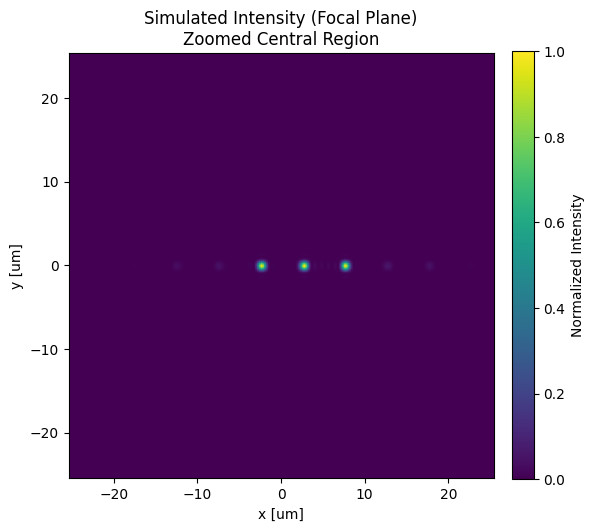

In [20]:
U_foc = PM.simulate_focal_plane(hologram1, Nx_pad=2048*2, Ny_pad=2048*2, show=True, zoom_pixels=30, cmap='viridis')

In [21]:
terms = [np.array([1, 1, 1]), 
        np.random.uniform(-np.pi/2, np.pi/2, size=(3,)), 
        np.array([-2.5, 2.5, -7.5]), 
        np.array([0, 0, 0]),
        np.array([0, 0, 0])]

hologram2, terms_opt2, metrics = PM.superposition_optimization(terms, max_iter=2000, damping=0.35, verbose=True)

--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.18e-03 | Uniformity: 89.69% | Min/Max ratio: 0.805
Iteration 010 | Mean-Squared Error: 3.65e-09 | Uniformity: 99.98% | Min/Max ratio: 1.000
Iteration 020 | Mean-Squared Error: 2.98e-09 | Uniformity: 99.98% | Min/Max ratio: 1.000
Iteration 030 | Mean-Squared Error: 4.29e-09 | Uniformity: 99.98% | Min/Max ratio: 1.000
Iteration 040 | Mean-Squared Error: 6.24e-09 | Uniformity: 99.98% | Min/Max ratio: 0.999
Iteration 050 | Mean-Squared Error: 9.16e-09 | Uniformity: 99.97% | Min/Max ratio: 0.999
Iteration 060 | Mean-Squared Error: 1.35e-08 | Uniformity: 99.97% | Min/Max ratio: 0.999
Iteration 070 | Mean-Squared Error: 2.00e-08 | Uniformity: 99.96% | Min/Max ratio: 0.999
Iteration 080 | Mean-Squared Error: 2.93e-08 | Uniformity: 99.95% | Min/Max ratio: 0.999
Iteration 090 | Mean-Squared Error: 4.16e-08 | Uniformity: 99.94% | Min/Max ratio: 0.999
Iteration 100 | Mean-Squared Error: 5.55e-08 | Uniform

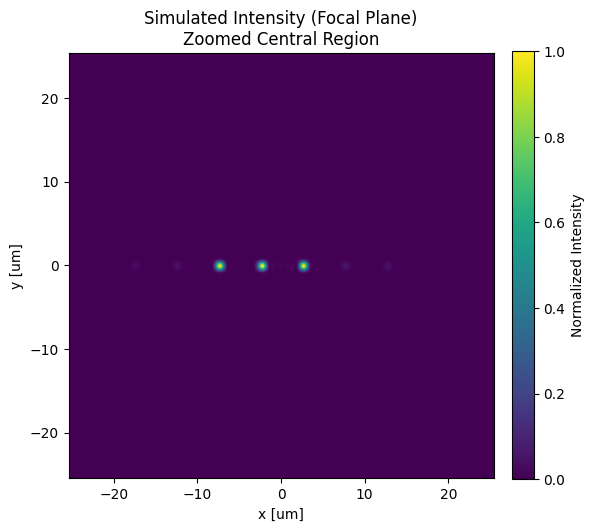

In [23]:
U_foc = PM.simulate_focal_plane(hologram2, Nx_pad=2048*2, Ny_pad=2048*2, show=True, zoom_pixels=30, cmap='viridis')

In [74]:
from pytweezer.phasemask import linear_path, lift_path
import cupy as cp

d = 10
path = lift_path(d, smooth_corners=True)

frames = PM.iter_transport_sequence_3D(terms_opt1, terms_opt2, d0=1.0, d0_z=1.5,
                                profile="linear", path_fn=path,
                                step_norm="max", to_host=False,
                                refine_iters=1, refine_damping=0.35,
                                init_refine_iters=1, init_refine_damping=0.35)

holograms = [PM.superimpose([frame/PM.uint8_scale - cp.pi, -PM.fresnel, -PM.blaze, - PM.zernike])for frame in frames]

Text(0, 0.5, 'z [um]')

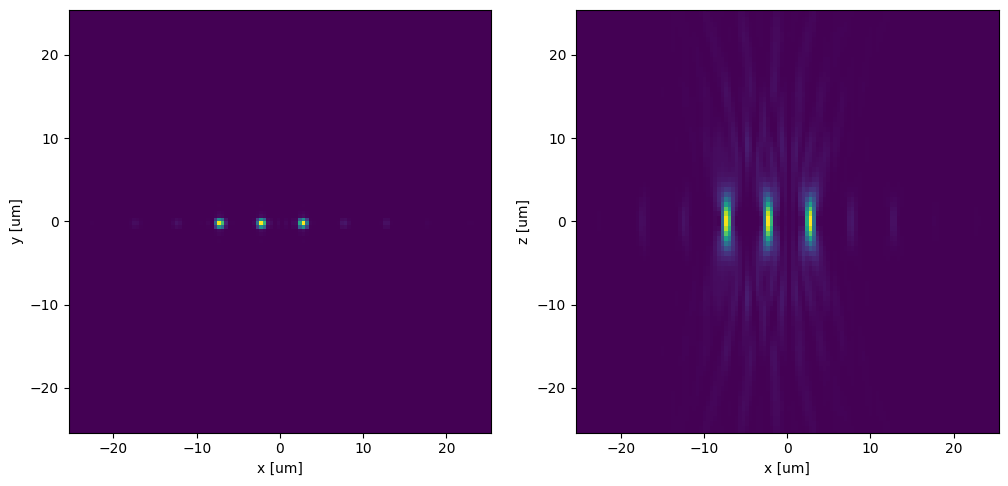

In [75]:
n = -1
hologram_n = holograms[n]

I_n, phi_n = PM.evaluate_traps(hologram_n, terms_opt2[2], terms_opt2[3], terms_opt2[4])
U_foc = simulate_focal_field(hologram_n, Nx_pad=2048, Ny_pad=2048, show=False, zoom_pixels=30, z_range=(-30, 30), z_resolution=100, cmap='viridis')
I_foc = np.abs(U_foc)**2

fig, ax = plt.subplots(1, 2, figsize=(6*2, 6))
zoom_range_um = 30 * PM.dx_f
x_focal_um = np.linspace(-PM.Nx*PM.dx_f/2, PM.Nx*PM.dx_f/2, 2048)
y_focal_um = np.linspace(-PM.Ny*PM.dy_f/2, PM.Ny*PM.dy_f/2, 2048)
z_focal_um = np.linspace(-30, 30, 100)  # Assuming z_range=(-30, 30) and z_resolution=100

I_foc_xy = I_foc[50, :, :]  # Sum over z-axis to get the xy-plane intensity
norm_intensity_xy = I_foc_xy / I_foc_xy.max()
im1 = ax[0].imshow(norm_intensity_xy, 
                extent=[x_focal_um[0], x_focal_um[-1], y_focal_um[0], y_focal_um[-1]],
                cmap='viridis')
ax[0].set_xlim(-zoom_range_um, zoom_range_um)
ax[0].set_ylim(-zoom_range_um, zoom_range_um)
ax[0].grid(False)
ax[0].set_xlabel("x [um]")
ax[0].set_ylabel("y [um]")

I_foc_xz = I_foc[:, 2048//2, :]  # Sum over z-axis to get the xz-plane intensity
norm_intensity_xz = I_foc_xz / I_foc_xz.max()
im2 = ax[1].imshow(norm_intensity_xz, 
                extent=[x_focal_um[0], x_focal_um[-1], z_focal_um[0], z_focal_um[-1]],
                cmap='viridis')
ax[1].set_xlim(-zoom_range_um, zoom_range_um)
ax[1].set_ylim(-zoom_range_um, zoom_range_um)
ax[1].grid(False)
ax[1].set_xlabel("x [um]")
ax[1].set_ylabel("z [um]")

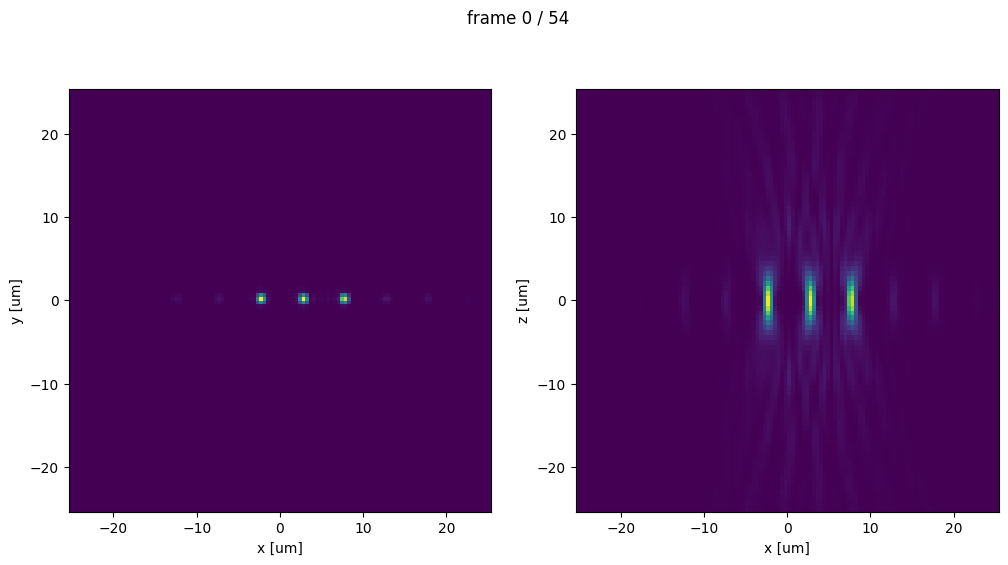

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

zoom_range_um = 30 * PM.dx_f
x_focal_um = np.linspace(-PM.Nx*PM.dx_f/2, PM.Nx*PM.dx_f/2, 2048)
y_focal_um = np.linspace(-PM.Ny*PM.dy_f/2, PM.Ny*PM.dy_f/2, 2048)
z_focal_um = np.linspace(-30, 30, 100)

def get_planes(n):
    """Your single-frame calculation for hologram n."""
    hologram_n = holograms[n]
    U_foc = simulate_focal_field(hologram_n, Nx_pad=2048, Ny_pad=2048, show=False,
                                 zoom_pixels=30, z_range=(-30, 30), z_resolution=100,
                                 cmap='viridis')
    I_foc = np.abs(U_foc)**2
    I_foc_xy = I_foc[50, :, :]
    I_foc_xz = I_foc[:, 2048//2, :]
    return I_foc_xy / I_foc_xy.max(), I_foc_xz / I_foc_xz.max()

# --- set up the figure once, using the first hologram
fig, ax = plt.subplots(1, 2, figsize=(6*2, 6))
norm_intensity_xy, norm_intensity_xz = get_planes(0)

im1 = ax[0].imshow(norm_intensity_xy,
                   extent=[x_focal_um[0], x_focal_um[-1], y_focal_um[0], y_focal_um[-1]],
                   origin='lower', cmap='viridis')
ax[0].set_xlim(-zoom_range_um, zoom_range_um)
ax[0].set_ylim(-zoom_range_um, zoom_range_um)
ax[0].grid(False)
ax[0].set_xlabel("x [um]")
ax[0].set_ylabel("y [um]")

im2 = ax[1].imshow(norm_intensity_xz,
                   extent=[x_focal_um[0], x_focal_um[-1], z_focal_um[0], z_focal_um[-1]],
                   origin='lower', cmap='viridis')
ax[1].set_xlim(-zoom_range_um, zoom_range_um)
ax[1].set_ylim(-zoom_range_um, zoom_range_um)
ax[1].grid(False)
ax[1].set_xlabel("x [um]")
ax[1].set_ylabel("z [um]")

title = fig.suptitle("")

# --- called once per animation frame with n = 0, 1, 2, ...
def update(n):
    norm_intensity_xy, norm_intensity_xz = get_planes(n)
    im1.set_data(norm_intensity_xy)
    im2.set_data(norm_intensity_xz)
    title.set_text(f"frame {n} / {len(holograms) - 1}")
    return im1, im2, title

anim = FuncAnimation(fig, update, frames=len(holograms), interval=100, repeat=True)

# save as a looping GIF
anim.save("transport.gif", writer=PillowWriter(fps=10))

# or, in Jupyter, view inline:
from IPython.display import HTML
HTML(anim.to_jshtml())

In [77]:
anim.save("../Plotting/transport.gif", writer=PillowWriter(fps=10))

---

In [20]:
weights = np.ones((9, 9))
spacing = 3.0
w_n, theta_n, x_n, y_n, z_n = PM.generate_weighted_array(weights, 5.0)

for i in range(len(z_n)):
    if i % 2 == 0:
        z_n[i] += 5.0

terms = [w_n, theta_n, x_n, y_n, z_n]
hologram, terms_opt, metrics = PM.superposition_optimization(terms, max_iter=2000, damping=0.35, verbose=True)

--- Target Generation ---
Grid: 9x9
Spacing: 5.0 um
--- Starting GPU Superposition Phase Retrieval (3D) ---
Iteration 000 | Mean-Squared Error: 1.53e-05 | Uniformity: 68.30% | Min/Max ratio: 0.168
Iteration 010 | Mean-Squared Error: 2.27e-07 | Uniformity: 96.14% | Min/Max ratio: 0.838
Iteration 020 | Mean-Squared Error: 3.83e-08 | Uniformity: 98.41% | Min/Max ratio: 0.929
Iteration 030 | Mean-Squared Error: 2.17e-08 | Uniformity: 98.81% | Min/Max ratio: 0.947
Iteration 040 | Mean-Squared Error: 9.46e-09 | Uniformity: 99.21% | Min/Max ratio: 0.963
Iteration 050 | Mean-Squared Error: 9.51e-09 | Uniformity: 99.21% | Min/Max ratio: 0.961
Iteration 060 | Mean-Squared Error: 7.13e-09 | Uniformity: 99.32% | Min/Max ratio: 0.963
Iteration 070 | Mean-Squared Error: 4.30e-09 | Uniformity: 99.47% | Min/Max ratio: 0.974
Iteration 080 | Mean-Squared Error: 1.94e-09 | Uniformity: 99.64% | Min/Max ratio: 0.985
Iteration 090 | Mean-Squared Error: 1.67e-09 | Uniformity: 99.67% | Min/Max ratio: 0.984
It

Text(0, 0.5, 'z [um]')

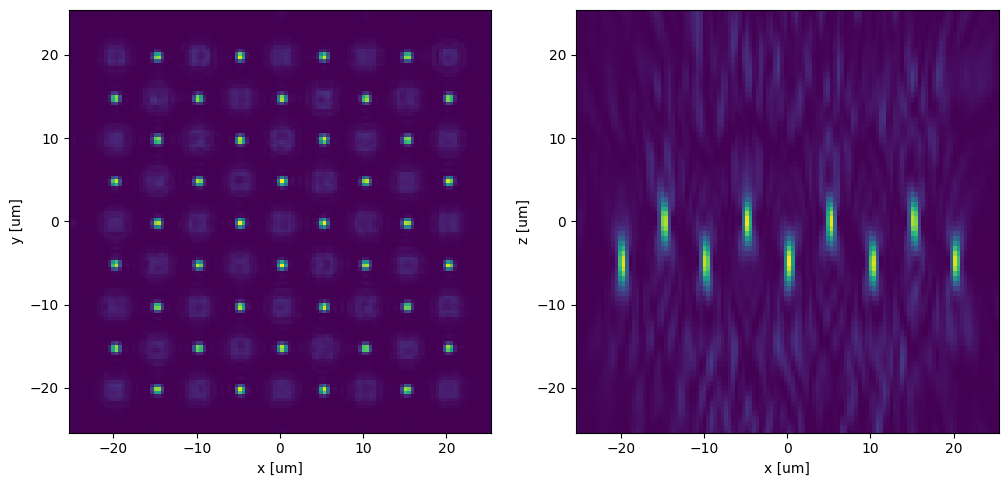

In [24]:
hologram_n = hologram
nx_pad, ny_pad = 2048, 2048
z_range=(-30, 30)
z_resolution=100
zoom=30

cmap='viridis'

U_foc = simulate_focal_field(hologram_n, Nx_pad=nx_pad, Ny_pad=ny_pad, show=False, zoom_pixels=zoom, z_range=z_range, z_resolution=z_resolution)
I_foc = np.abs(U_foc)**2

fig, ax = plt.subplots(1, 2, figsize=(6*2, 6))
zoom_range_um = zoom * PM.dx_f
x_focal_um = np.linspace(-PM.Nx*PM.dx_f/2, PM.Nx*PM.dx_f/2, nx_pad)
y_focal_um = np.linspace(-PM.Ny*PM.dy_f/2, PM.Ny*PM.dy_f/2, ny_pad)
z_focal_um = np.linspace(z_range[0], z_range[1], z_resolution)  # Assuming z_range=(-30, 30) and z_resolution=100

I_foc_xy = I_foc[z_resolution//2, :, :]  # Sum over z-axis to get the xy-plane intensity
norm_intensity_xy = I_foc_xy / I_foc_xy.max()
im1 = ax[0].imshow(norm_intensity_xy, 
                extent=[x_focal_um[0], x_focal_um[-1], y_focal_um[0], y_focal_um[-1]],
                cmap=cmap)
ax[0].set_xlim(-zoom_range_um, zoom_range_um)
ax[0].set_ylim(-zoom_range_um, zoom_range_um)
ax[0].grid(False)
ax[0].set_xlabel("x [um]")
ax[0].set_ylabel("y [um]")

I_foc_xz = I_foc[:, nx_pad//2, :]  # Sum over z-axis to get the xz-plane intensity
norm_intensity_xz = I_foc_xz / I_foc_xz.max()
im2 = ax[1].imshow(norm_intensity_xz, 
                extent=[x_focal_um[0], x_focal_um[-1], z_focal_um[0], z_focal_um[-1]],
                cmap=cmap)
ax[1].set_xlim(-zoom_range_um, zoom_range_um)
ax[1].set_ylim(-zoom_range_um, zoom_range_um)
ax[1].grid(False)
ax[1].set_xlabel("x [um]")
ax[1].set_ylabel("z [um]")